In [1]:
# STEP 1: Import Libraries
import os
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import cv2
import seaborn as sns
import random

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.data import AUTOTUNE

from sklearn.metrics import classification_report, confusion_matrix

In [2]:
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.10.0


In [3]:
# STEP 2: Dataset Loading and Path Configuration
dataset_path = r"C:\Users\Yashw\Downloads\Kidney Stone Dataset"

print("Classes:", os.listdir(dataset_path))

Classes: ['Non Stone', 'Stone']


In [4]:
# STEP 3: Exploratory Data Analysis(EDA)
stone_path = os.path.join(dataset_path, "Stone")
nonstone_path = os.path.join(dataset_path, "Non Stone")

stone_count = len(os.listdir(stone_path))
nonstone_count = len(os.listdir(nonstone_path))

print("Stone images:", stone_count)
print("Non-stone images:", nonstone_count)
print("Total images:", stone_count + nonstone_count)

Stone images: 17794
Non-stone images: 14470
Total images: 32264


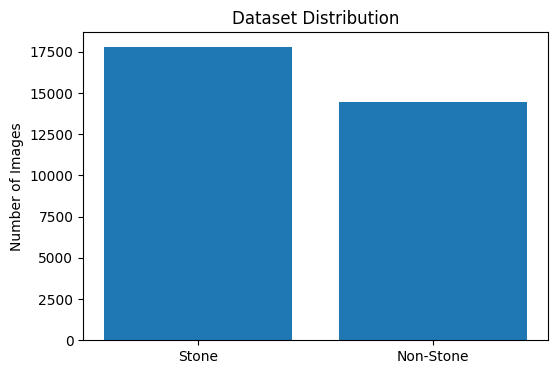

In [5]:
# STEP 3.1: Dataset Class Distribution Analysis
import matplotlib.pyplot as plt

labels = ['Stone', 'Non-Stone']
counts = [stone_count, nonstone_count]

plt.figure(figsize=(6,4))
plt.bar(labels, counts)
plt.title("Dataset Distribution")
plt.ylabel("Number of Images")
plt.show()

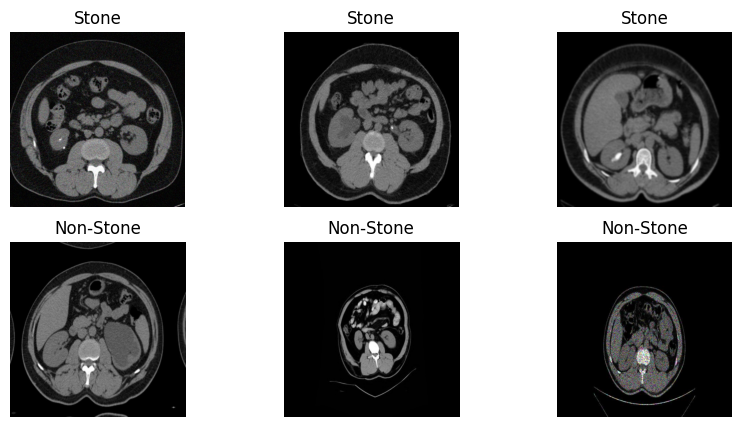

In [6]:
# STEP 3.2: Sample Image Visualization from Each Class
import random
import cv2

plt.figure(figsize=(10,5))

for i in range(6):
    
    if i < 3:
        img_path = os.path.join(stone_path, random.choice(os.listdir(stone_path)))
        label = "Stone"
    else:
        img_path = os.path.join(nonstone_path, random.choice(os.listdir(nonstone_path)))
        label = "Non-Stone"
        
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    plt.subplot(2,3,i+1)
    plt.imshow(img)
    plt.title(label)
    plt.axis("off")

plt.show()

In [7]:
# STEP 4: Dataset Preprocessing and Train-Validation Split
# STEP 4.1: Define Image Parameters

print("Defining image parameters...")

img_size = 128
batch_size = 8

print("img_size =", img_size)
print("batch_size =", batch_size)

Defining image parameters...
img_size = 128
batch_size = 8


In [8]:
# STEP 4.2: Create Training Dataset

print("Loading training dataset...")

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(img_size, img_size),
    batch_size=batch_size
)

print("Training dataset loaded successfully.")

Loading training dataset...
Found 32264 files belonging to 2 classes.
Using 25812 files for training.
Training dataset loaded successfully.


In [9]:
# STEP 4.3: Create Validation Dataset
print("Loading validation dataset...")

val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(img_size, img_size),
    batch_size=batch_size
)

print("Validation dataset loaded successfully.")

Loading validation dataset...
Found 32264 files belonging to 2 classes.
Using 6452 files for validation.
Validation dataset loaded successfully.


In [10]:
# STEP 4.4: Get Class Names
class_names = train_ds.class_names
print("Class Names:", class_names)

Class Names: ['Non Stone', 'Stone']


In [11]:
# STEP 4.5: Image Normalization and Dataset Performance Optimization

print("Applying normalization... Please wait.")

normalization_layer = tf.keras.layers.Rescaling(1./255)

# Apply normalization
train_ds = train_ds.map(
    lambda x, y: (normalization_layer(x), y),
    num_parallel_calls=1   # fixed threads instead of AUTOTUNE
)

val_ds = val_ds.map(
    lambda x, y: (normalization_layer(x), y),
    num_parallel_calls=1
)

# prefetch
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)

print("Normalization applied successfully.")

Applying normalization... Please wait.
Normalization applied successfully.


In [12]:
# STEP 4.6: Enable GPU Memory Growth

import tensorflow as tf

gpus = tf.config.experimental.list_physical_devices('GPU')

if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("GPU memory growth enabled")
    except RuntimeError as e:
        print(e)

Physical devices cannot be modified after being initialized


In [13]:
# STEP 4.7: Define Data Augmentation

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1),
])
print("Data augmentation layer created successfully.")

Data augmentation layer created successfully.


In [14]:
# STEP 4.8: Apply Data Augmentation to Training Dataset

train_ds = train_ds.map(
    lambda x, y: (data_augmentation(x, training=True), y),
    num_parallel_calls=1
)

train_ds = train_ds.prefetch(tf.data.AUTOTUNE)

print("Data augmentation applied successfully.")

Data augmentation applied successfully.


In [15]:
# STEP 4.9: Early Stopping Configuration

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

print("Early stopping configured.")

Early stopping configured.


In [16]:
# STEP 5: CNN Model Architecture
# STEP 5.1: Build High-Performance CNN Model

print("Building high-accuracy pure CNN model...")

model = tf.keras.models.Sequential([

    # Input Layer
    tf.keras.layers.Input(shape=(img_size, img_size, 3)),

    # Convolution Block 1
    tf.keras.layers.Conv2D(32, (3,3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D(2,2),

    # Convolution Block 2
    tf.keras.layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D(2,2),

    # Convolution Block 3
    tf.keras.layers.Conv2D(128, (3,3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D(2,2),

    # Convolution Block 4
    tf.keras.layers.Conv2D(256, (3,3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D(2,2),

    # Convolution Block 5 (NEW - improves accuracy)
    tf.keras.layers.Conv2D(512, (3,3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D(2,2),

    # Replace Flatten with GlobalAveragePooling (reduces overfitting)
    tf.keras.layers.GlobalAveragePooling2D(),

    # Fully Connected Layer with L2 regularization
    tf.keras.layers.Dense(
        256,
        activation='relu',
        kernel_regularizer=tf.keras.regularizers.l2(0.001)
    ),

    # Dropout prevents overfitting
    tf.keras.layers.Dropout(0.5),

    # Output Layer
    tf.keras.layers.Dense(1, activation='sigmoid')

])

print("Pure CNN model built successfully.")

Building high-accuracy pure CNN model...
Pure CNN model built successfully.


In [17]:
# STEP 5.2: Compile Model

model.compile(

    optimizer='adam',

    loss='binary_crossentropy',

    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]

)

print("Model compiled successfully.")

Model compiled successfully.


In [18]:
# STEP 5.3: View Model Summary
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 128, 128, 32)      896       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 64, 64, 32)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 64, 64, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 32, 32, 64)       0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (None, 32, 32, 128)       73856     
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 16, 16, 128)     

In [19]:
# STEP 6: Training and Learning Rate Configuration
# STEP 6.1: Define Optimizer

lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    verbose=1
)
optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0003
)

print("Optimizer defined successfully.")

Optimizer defined successfully.


In [20]:
# STEP 6.2: Compile Model

model.compile(
    optimizer=optimizer,
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

print("Model compiled successfully.")

Model compiled successfully.


In [21]:
# STEP 6.3: Train the CNN Model

import gc
gc.collect()
tf.keras.backend.clear_session()

epochs = 30

history = model.fit(

    train_ds,
    
    validation_data=val_ds,
    
    epochs=epochs,

    callbacks=[early_stop, lr_scheduler],

    
    verbose = 1

)

print("Training completed successfully.")

Epoch 1/30
3227/3227 [==============================] - 193s 58ms/step - loss: 0.6222 - accuracy: 0.6761 - precision: 0.6901 - recall: 0.7463 - val_loss: 0.3863 - val_accuracy: 0.8456 - val_precision: 0.8581 - val_recall: 0.8662 - lr: 3.0000e-04
Epoch 2/30
3227/3227 [==============================] - 188s 58ms/step - loss: 0.3485 - accuracy: 0.8556 - precision: 0.8875 - recall: 0.8447 - val_loss: 0.1875 - val_accuracy: 0.9289 - val_precision: 0.9524 - val_recall: 0.9182 - lr: 3.0000e-04
Epoch 3/30
3227/3227 [==============================] - 186s 58ms/step - loss: 0.2194 - accuracy: 0.9167 - precision: 0.9394 - recall: 0.9070 - val_loss: 0.1864 - val_accuracy: 0.9340 - val_precision: 0.9853 - val_recall: 0.8949 - lr: 3.0000e-04
Epoch 4/30
3227/3227 [==============================] - 187s 58ms/step - loss: 0.1719 - accuracy: 0.9369 - precision: 0.9564 - recall: 0.9275 - val_loss: 0.1038 - val_accuracy: 0.9626 - val_precision: 0.9838 - val_recall: 0.9486 - lr: 3.0000e-04
Epoch 5/30
3227/

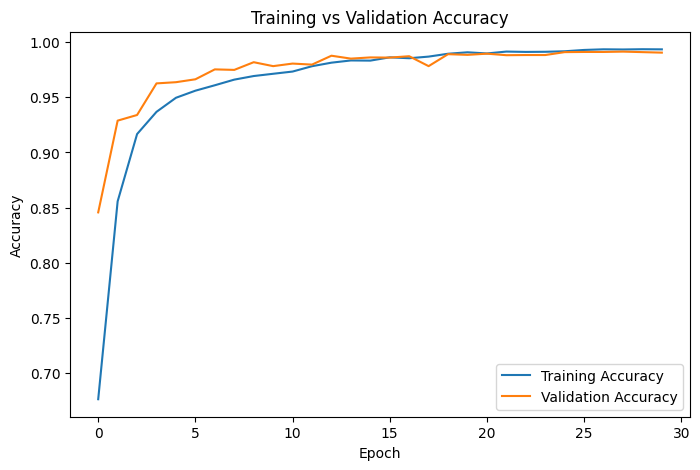

In [22]:
# STEP 6.4: Training vs Validation Accuracy Graph
plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Training Accuracy')

plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("Training vs Validation Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.show()

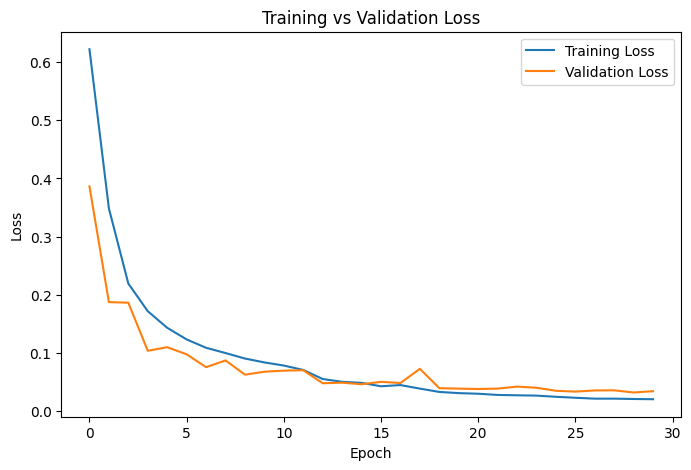

In [23]:
# STEP 6.5: Training vs Validation Loss Graph
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Training Loss')

plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Training vs Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.show()

In [24]:
# STEP 6.6: Save Trained Model
model.save("kidney_stone_pureCNN.keras")

print("Model saved successfully.")

Model saved successfully.


In [48]:
from tensorflow.keras.models import load_model

model = load_model("kidney_stone_pureCNN.keras")

print("Model loaded successfully.")

Model loaded successfully.


In [19]:
# STEP 7.1: Evaluate Model on Validation Dataset
val_loss, val_accuracy, val_precision, val_recall = model.evaluate(val_ds)

print("Validation Loss:", val_loss)
print("Validation Accuracy:", val_accuracy)
print("Validation Precision:", val_precision)
print("Validation Recall:", val_recall)

807/807 [==============================] - 9s 10ms/step - loss: 0.0344 - accuracy: 0.9905 - precision: 0.9928 - recall: 0.9903
Validation Loss: 0.03435203433036804
Validation Accuracy: 0.9905455708503723
Validation Precision: 0.9927516579627991
Validation Recall: 0.9902669191360474


In [20]:
# STEP 7.2: Get True Labels and Predictions
import numpy as np

y_true = []
y_pred = []

for images, labels in val_ds:
    
    predictions = model.predict(images)
    
    predicted_labels = (predictions > 0.5).astype(int)
    
    y_true.extend(labels.numpy())
    
    y_pred.extend(predicted_labels.flatten())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Predictions generated successfully.")

1/1 [==============================] - 0s 31ms/step
Predictions generated successfully.


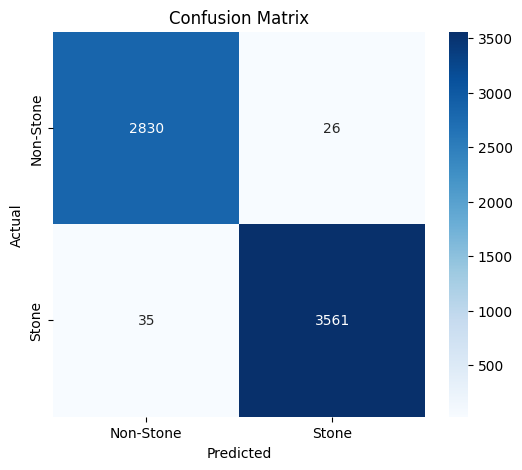

In [21]:
# STEP 7.3: Confusion Matrix

from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Non-Stone", "Stone"],
            yticklabels=["Non-Stone", "Stone"])

plt.title("Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

In [22]:
# STEP 7.4: Classification Report(Precision,Recall,F1,Score)
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=["Non-Stone", "Stone"]
))

              precision    recall  f1-score   support

   Non-Stone       0.99      0.99      0.99      2856
       Stone       0.99      0.99      0.99      3596

    accuracy                           0.99      6452
   macro avg       0.99      0.99      0.99      6452
weighted avg       0.99      0.99      0.99      6452



1/1 [==============================] - 0s 16ms/step


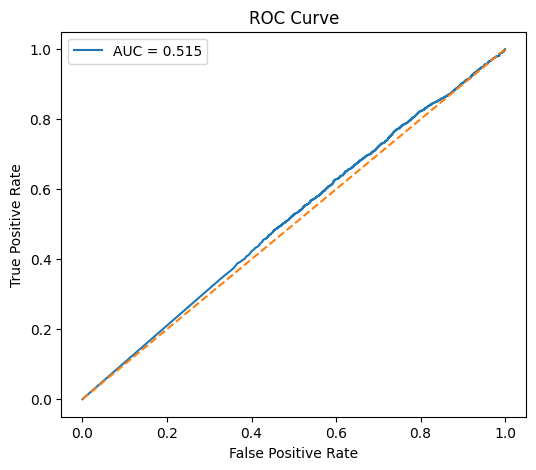

AUC Score: 0.5151823590949172


In [23]:
# STEP 8: ROC Curve and AUC Score
from sklearn.metrics import roc_curve, auc

y_prob = []

for images, labels in val_ds:
    
    predictions = model.predict(images)
    
    y_prob.extend(predictions.flatten())

y_prob = np.array(y_prob)

fpr, tpr, thresholds = roc_curve(y_true, y_prob)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))

plt.plot(fpr, tpr, label="AUC = %.3f" % roc_auc)

plt.plot([0,1], [0,1], linestyle="--")

plt.title("ROC Curve")

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.legend()

plt.show()

print("AUC Score:", roc_auc)

In [49]:
# STEP 9: Predict Single Image
from tensorflow.keras.preprocessing import image

img_path = r"C:\Users\yashw\Downloads\Kidney Stone Dataset\Stone\P195_RA_F_S_I19_EL.jpg"
# replace with real image path

img = image.load_img(img_path, target_size=(128,128))

img_array = image.img_to_array(img)

img_array = np.expand_dims(img_array, axis=0)

img_array = img_array / 255.0

prediction = model.predict(img_array)

confidence = prediction[0][0]

if confidence > 0.5:
    print("Prediction: Stone")
    print("Confidence:", confidence)
else:
    print("Prediction: Non-Stone")
    print("Confidence:", 1-confidence)

1/1 [==============================] - 0s 105ms/step
Prediction: Stone
Confidence: 1.0


In [51]:
# STEP 10: Professional Prediction Function
# STEP 10.1: Define Function
def predict_kidney_stone(img_path):
    
    img = image.load_img(img_path, target_size=(128,128))
    
    img_array = image.img_to_array(img)
    
    img_array = np.expand_dims(img_array, axis=0)
    
    img_array = img_array / 255.0
    
    prediction = model.predict(img_array)
    
    confidence = prediction[0][0]
    
    if confidence > 0.5:
        print("Prediction: Stone")
        print("Confidence:", confidence)
    else:
        print("Prediction: Non-Stone")
        print("Confidence:", 1-confidence)

In [52]:
# STEP 10.2: Call Function
predict_kidney_stone(r"C:\Users\yashw\Downloads\Kidney Stone Dataset\Non Stone\P117_RA_M_NS_I11_EL.jpg")

1/1 [==============================] - 0s 29ms/step
Prediction: Non-Stone
Confidence: 0.9999946034631648


In [27]:
# STEP 11: Save Accuracy for Comparision
model_accuracies = {}
print("Accuracy storage initialized.")
model_accuracies["Pure CNN"] = 0.9905455708503723
print("Pure CNN accuracy added.")

Accuracy storage initialized.
Pure CNN accuracy added.


In [28]:
# STEP 12: Clear memory

import gc
tf.keras.backend.clear_session()
gc.collect()

print("Memory cleared successfully.")

Memory cleared successfully.


In [29]:
# STEP 13: CNN Model Architecture with Batch Normalization
# STEP 13.1: Build High-Performance CNN Model with Batch Normalization

print("Building CNN with Batch Normalization...")

model = tf.keras.models.Sequential([

    tf.keras.layers.Input(shape=(img_size, img_size, 3)),

    tf.keras.layers.Conv2D(32, (3,3), padding='same',
                           kernel_initializer='he_normal',
                           kernel_regularizer=tf.keras.regularizers.l2(0.0005)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(2),

    tf.keras.layers.Conv2D(64, (3,3), padding='same',
                           kernel_initializer='he_normal',
                           kernel_regularizer=tf.keras.regularizers.l2(0.0005)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(2),

    tf.keras.layers.Conv2D(128, (3,3), padding='same',
                           kernel_initializer='he_normal',
                           kernel_regularizer=tf.keras.regularizers.l2(0.0005)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(2),

    tf.keras.layers.Conv2D(256, (3,3), padding='same',
                           kernel_initializer='he_normal',
                           kernel_regularizer=tf.keras.regularizers.l2(0.0005)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(2),

    tf.keras.layers.Conv2D(512, (3,3), padding='same',
                           kernel_initializer='he_normal',
                           kernel_regularizer=tf.keras.regularizers.l2(0.0005)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(2),

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(256,
                          kernel_initializer='he_normal',
                          kernel_regularizer=tf.keras.regularizers.l2(0.001)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),

    tf.keras.layers.Dense(128,
                          kernel_initializer='he_normal'),
    tf.keras.layers.Activation('relu'),

    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(1, activation='sigmoid')

])

print("BatchNorm CNN ready.")

Building CNN with Batch Normalization...
BatchNorm CNN ready.


In [30]:
# STEP 13.2: Compile Model

model.compile(

    optimizer='adam',

    loss='binary_crossentropy',

    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]

)

print("Model compiled successfully.")

Model compiled successfully.


In [31]:
# STEP 13.3: View Model Summary
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 128, 128, 32)      896       
                                                                 
 batch_normalization (BatchN  (None, 128, 128, 32)     128       
 ormalization)                                                   
                                                                 
 activation (Activation)     (None, 128, 128, 32)      0         
                                                                 
 max_pooling2d (MaxPooling2D  (None, 64, 64, 32)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 64, 64, 64)        18496     
                                                                 
 batch_normalization_1 (Batc  (None, 64, 64, 64)       2

In [32]:
# STEP 14: Training and Learning Rate Configuration
# STEP 14.1: Define Optimizer

lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    verbose=1
)
optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0003
)

print("Optimizer defined successfully.")

Optimizer defined successfully.


In [33]:
# STEP 14.2: Compile Model

model.compile(
    optimizer=optimizer,
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

print("Model compiled successfully.")

Model compiled successfully.


In [34]:
# STEP 14.3: Train the CNN Model

import gc
gc.collect()
tf.keras.backend.clear_session()

epochs = 30

history = model.fit(

    train_ds,
    
    validation_data=val_ds,
    
    epochs=epochs,

    callbacks=[early_stop, lr_scheduler],

    verbose = 1

)

print("Training completed successfully.")

Epoch 1/30
3227/3227 [==============================] - 198s 61ms/step - loss: 1.6117 - accuracy: 0.7135 - precision: 0.7450 - recall: 0.7286 - val_loss: 1.4202 - val_accuracy: 0.7168 - val_precision: 0.9465 - val_recall: 0.5214 - lr: 3.0000e-04
Epoch 2/30
3227/3227 [==============================] - 188s 58ms/step - loss: 0.8196 - accuracy: 0.8216 - precision: 0.8552 - recall: 0.8135 - val_loss: 1.1225 - val_accuracy: 0.6632 - val_precision: 0.6241 - val_recall: 0.9953 - lr: 3.0000e-04
Epoch 3/30
3227/3227 [==============================] - 192s 60ms/step - loss: 0.5795 - accuracy: 0.8618 - precision: 0.8967 - recall: 0.8464 - val_loss: 1.6896 - val_accuracy: 0.6012 - val_precision: 0.5830 - val_recall: 0.9986 - lr: 3.0000e-04
Epoch 4/30
3227/3227 [==============================] - 189s 59ms/step - loss: 0.4911 - accuracy: 0.8849 - precision: 0.9185 - recall: 0.8678 - val_loss: 0.4455 - val_accuracy: 0.8945 - val_precision: 0.9876 - val_recall: 0.8209 - lr: 3.0000e-04
Epoch 5/30
3227/

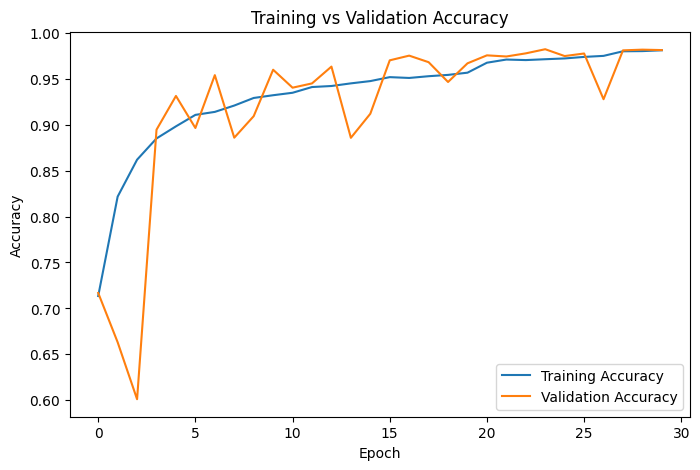

In [35]:
# STEP 14.4: Training vs Validation Accuracy Graph
plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Training Accuracy')

plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("Training vs Validation Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.show()

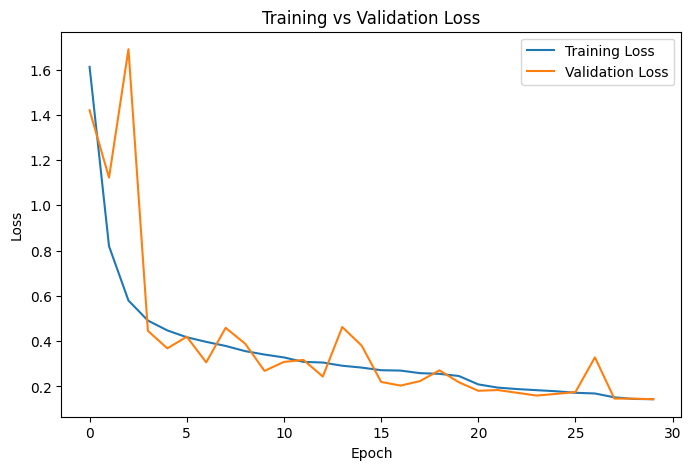

In [36]:
# STEP 14.5: Training vs Validation Loss Graph
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Training Loss')

plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Training vs Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.show()

In [37]:
# STEP 14.6: Save Trained Model
model.save("kidney_stone_BatchNorm.keras")

print("Model saved successfully.")

Model saved successfully.


In [53]:
from tensorflow.keras.models import load_model

model = load_model("kidney_stone_BatchNorm.keras")

print("Model loaded successfully.")

Model loaded successfully.


In [38]:
# STEP 15.1: Evaluate Model on Validation Dataset
val_loss, val_accuracy, val_precision, val_recall = model.evaluate(val_ds)

print("Validation Loss:", val_loss)
print("Validation Accuracy:", val_accuracy)
print("Validation Precision:", val_precision)
print("Validation Recall:", val_recall)

807/807 [==============================] - 11s 14ms/step - loss: 0.1435 - accuracy: 0.9811 - precision: 0.9960 - recall: 0.9700
Validation Loss: 0.14345437288284302
Validation Accuracy: 0.9810911417007446
Validation Precision: 0.9960023164749146
Validation Recall: 0.9699665904045105


In [39]:
# STEP 15.2: Get True Labels and Predictions
import numpy as np

y_true = []
y_pred = []

for images, labels in val_ds:
    
    predictions = model.predict(images)
    
    predicted_labels = (predictions > 0.5).astype(int)
    
    y_true.extend(labels.numpy())
    
    y_pred.extend(predicted_labels.flatten())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Predictions generated successfully.")

1/1 [==============================] - 0s 26ms/step
Predictions generated successfully.


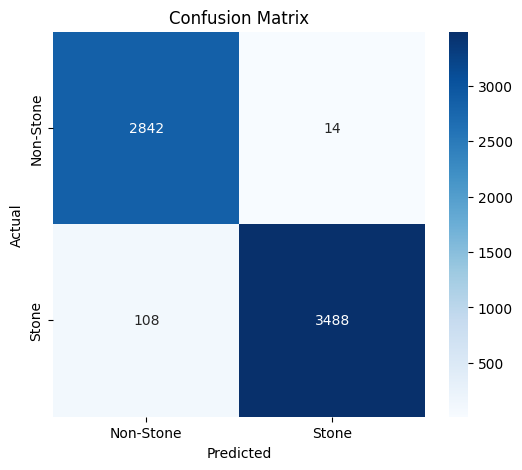

In [40]:
# STEP 15.3: Confusion Matrix

from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Non-Stone", "Stone"],
            yticklabels=["Non-Stone", "Stone"])

plt.title("Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

In [41]:
# STEP 15.4: Classification Report(Precision,Recall,F1,Score)
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=["Non-Stone", "Stone"]
))

              precision    recall  f1-score   support

   Non-Stone       0.96      1.00      0.98      2856
       Stone       1.00      0.97      0.98      3596

    accuracy                           0.98      6452
   macro avg       0.98      0.98      0.98      6452
weighted avg       0.98      0.98      0.98      6452



1/1 [==============================] - 0s 35ms/step


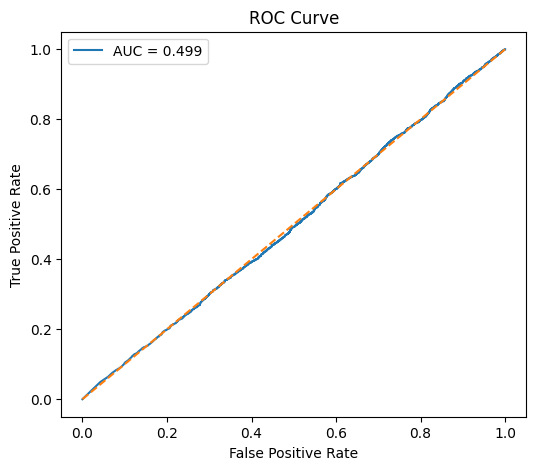

AUC Score: 0.49921369409832894


In [42]:
# STEP 16: ROC Curve and AUC Score
from sklearn.metrics import roc_curve, auc

y_prob = []

for images, labels in val_ds:
    
    predictions = model.predict(images)
    
    y_prob.extend(predictions.flatten())

y_prob = np.array(y_prob)

fpr, tpr, thresholds = roc_curve(y_true, y_prob)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))

plt.plot(fpr, tpr, label="AUC = %.3f" % roc_auc)

plt.plot([0,1], [0,1], linestyle="--")

plt.title("ROC Curve")

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.legend()

plt.show()

print("AUC Score:", roc_auc)

In [54]:
# STEP 17: Predict Single Image
from tensorflow.keras.preprocessing import image

img_path = r"C:\Users\yashw\Downloads\Kidney Stone Dataset\Stone\P195_RA_F_S_I19_EL.jpg"

img = image.load_img(img_path, target_size=(128,128))

img_array = image.img_to_array(img)

img_array = np.expand_dims(img_array, axis=0)

img_array = img_array / 255.0

prediction = model.predict(img_array)

confidence = prediction[0][0]
    
if confidence > 0.5:
        print("Prediction: Stone")
        print("Confidence:", confidence)
else:
        print("Prediction: Non-Stone")
        print("Confidence:", 1-confidence)

1/1 [==============================] - 0s 148ms/step
Prediction: Stone
Confidence: 1.0


In [55]:
# STEP 18: Professional Prediction Function
# STEP 18.1: Define Function
def predict_kidney_stone(img_path):
    
    img = image.load_img(img_path, target_size=(128,128))
    
    img_array = image.img_to_array(img)
    
    img_array = np.expand_dims(img_array, axis=0)
    
    img_array = img_array / 255.0
    
    prediction = model.predict(img_array)
    
    confidence = prediction[0][0]
    
    if confidence > 0.5:
        print("Prediction: Stone")
        print("Confidence:", confidence)
    else:
        print("Prediction: Non-Stone")
        print("Confidence:", 1-confidence)

In [56]:
# STEP 18.2: Call Function
predict_kidney_stone(r"C:\Users\yashw\Downloads\Kidney Stone Dataset\Non Stone\P117_RA_M_NS_I11_EL.jpg")

1/1 [==============================] - 0s 32ms/step
Prediction: Non-Stone
Confidence: 0.9999995902163334


In [33]:
# STEP 19: Save Accuracy for Comparision
model_accuracies = {}
print("Accuracy storage initialized.")
model_accuracies["Batch Norm"] =  0.9810911417007446
print("Batch Norm accuracy added.")

Accuracy storage initialized.
Batch Norm accuracy added.


In [51]:
# STEP 20: Clear memory

import gc
tf.keras.backend.clear_session()
gc.collect()

print("Memory cleared successfully.")

Memory cleared successfully.


In [16]:
# STEP 21: CNN Model Architecture with Layer Normalization
# STEP 21.1: Build High-Performance CNN Model with Layer Normalization

print("Building optimized CNN with Layer Normalization...")

model = tf.keras.models.Sequential([

    tf.keras.layers.Input(shape=(img_size, img_size, 3)),

    tf.keras.layers.Conv2D(32, (3,3), padding='same',
                           kernel_initializer='he_normal'),
    tf.keras.layers.LayerNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(2),

    tf.keras.layers.Conv2D(64, (3,3), padding='same',
                           kernel_initializer='he_normal'),
    tf.keras.layers.LayerNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(2),

    tf.keras.layers.Conv2D(128, (3,3), padding='same',
                           kernel_initializer='he_normal'),
    tf.keras.layers.LayerNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(2),

    tf.keras.layers.Conv2D(256, (3,3), padding='same',
                           kernel_initializer='he_normal'),
    tf.keras.layers.LayerNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(2),

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(256, kernel_initializer='he_normal'),
    tf.keras.layers.LayerNormalization(),
    tf.keras.layers.Activation('relu'),

    tf.keras.layers.Dropout(0.4),

    tf.keras.layers.Dense(1, activation='sigmoid')
])

Building optimized CNN with Layer Normalization...


In [17]:
# STEP 21.2: Compile Model

model.compile(

    optimizer='adam',

    loss='binary_crossentropy',

    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]

)

print("Model compiled successfully.")

Model compiled successfully.


In [18]:
# STEP 21.3: View Model Summary
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 128, 128, 32)      896       
                                                                 
 layer_normalization (LayerN  (None, 128, 128, 32)     64        
 ormalization)                                                   
                                                                 
 activation (Activation)     (None, 128, 128, 32)      0         
                                                                 
 max_pooling2d (MaxPooling2D  (None, 64, 64, 32)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 64, 64, 64)        18496     
                                                                 
 layer_normalization_1 (Laye  (None, 64, 64, 64)      

In [19]:
# STEP 22: Training Configuration
# STEP 22.1: Define Optimizer

lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    verbose=1
)
optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0001
)

print("Optimizer defined successfully.")

Optimizer defined successfully.


In [20]:
# STEP 22.2: Compile Model

model.compile(
    optimizer=optimizer,
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

print("Model compiled successfully.")

Model compiled successfully.


In [21]:
# STEP 22.3: Train the CNN Model

import gc
gc.collect()
tf.keras.backend.clear_session()

epochs = 30

history = model.fit(

    train_ds,
    
    validation_data=val_ds,
    
    epochs=epochs,

    callbacks=[early_stop, lr_scheduler],

    verbose = 1
    

)

print("Training completed successfully.")

Epoch 1/30
3227/3227 [==============================] - 203s 62ms/step - loss: 0.6700 - accuracy: 0.6067 - precision: 0.6172 - recall: 0.7506 - val_loss: 0.6548 - val_accuracy: 0.6159 - val_precision: 0.6106 - val_recall: 0.8579 - lr: 1.0000e-04
Epoch 2/30
3227/3227 [==============================] - 206s 64ms/step - loss: 0.6524 - accuracy: 0.6273 - precision: 0.6293 - recall: 0.7845 - val_loss: 0.6476 - val_accuracy: 0.6269 - val_precision: 0.6466 - val_recall: 0.7291 - lr: 1.0000e-04
Epoch 3/30
3227/3227 [==============================] - 205s 64ms/step - loss: 0.6450 - accuracy: 0.6341 - precision: 0.6398 - recall: 0.7660 - val_loss: 0.6427 - val_accuracy: 0.6254 - val_precision: 0.6710 - val_recall: 0.6432 - lr: 1.0000e-04
Epoch 4/30
3227/3227 [==============================] - 210s 65ms/step - loss: 0.6262 - accuracy: 0.6438 - precision: 0.6596 - recall: 0.7280 - val_loss: 0.6551 - val_accuracy: 0.5749 - val_precision: 0.7621 - val_recall: 0.3448 - lr: 1.0000e-04
Epoch 5/30
3227/

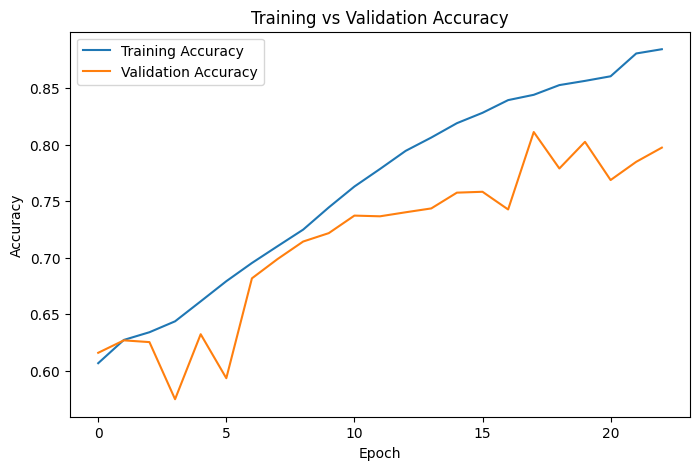

In [22]:
# STEP 22.4: Training vs Validation Accuracy Graph
plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Training Accuracy')

plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("Training vs Validation Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.show()

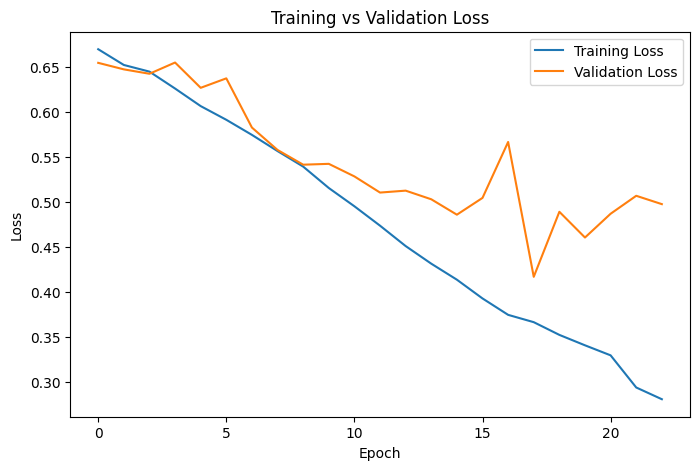

In [23]:
# STEP 22.5: Training vs Validation Loss Graph
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Training Loss')

plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Training vs Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.show()

In [24]:
# STEP 22.6: Save Trained Model
model.save("kidney_stone_LayerNorm.keras")

print("Model saved successfully.")

Model saved successfully.


In [57]:
from tensorflow.keras.models import load_model

model = load_model("kidney_stone_LayerNorm.keras")

print("Model loaded successfully.")

Model loaded successfully.


In [25]:
# STEP 23.1: Evaluate Model on Validation Dataset
val_loss, val_accuracy, val_precision, val_recall = model.evaluate(val_ds)

print("Validation Loss:", val_loss)
print("Validation Accuracy:", val_accuracy)
print("Validation Precision:", val_precision)
print("Validation Recall:", val_recall)

807/807 [==============================] - 10s 12ms/step - loss: 0.4168 - accuracy: 0.8112 - precision: 0.8208 - recall: 0.8459
Validation Loss: 0.4167749583721161
Validation Accuracy: 0.8112213611602783
Validation Precision: 0.8208310604095459
Validation Recall: 0.8459398746490479


In [26]:
# STEP 23.2: Get True Labels and Predictions
import numpy as np

y_true = []
y_pred = []

for images, labels in val_ds:
    
    predictions = model.predict(images)
    
    predicted_labels = (predictions > 0.5).astype(int)
    
    y_true.extend(labels.numpy())
    
    y_pred.extend(predicted_labels.flatten())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Predictions generated successfully.")

1/1 [==============================] - 0s 27ms/step
Predictions generated successfully.


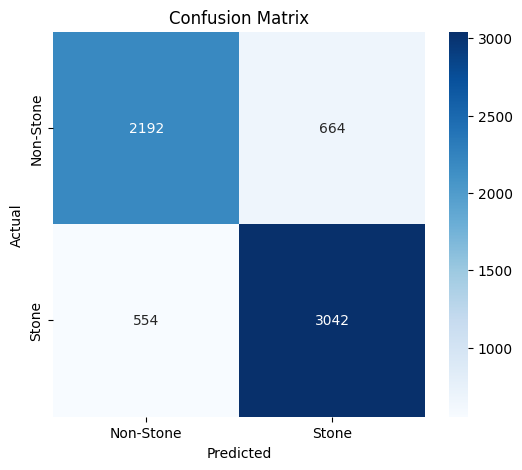

In [27]:
# STEP 23.3: Confusion Matrix

from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Non-Stone", "Stone"],
            yticklabels=["Non-Stone", "Stone"])

plt.title("Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

In [28]:
# STEP 23.4: Classification Report(Precision,Recall,F1,Score)
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=["Non-Stone", "Stone"]
))

              precision    recall  f1-score   support

   Non-Stone       0.80      0.77      0.78      2856
       Stone       0.82      0.85      0.83      3596

    accuracy                           0.81      6452
   macro avg       0.81      0.81      0.81      6452
weighted avg       0.81      0.81      0.81      6452



1/1 [==============================] - 0s 20ms/step


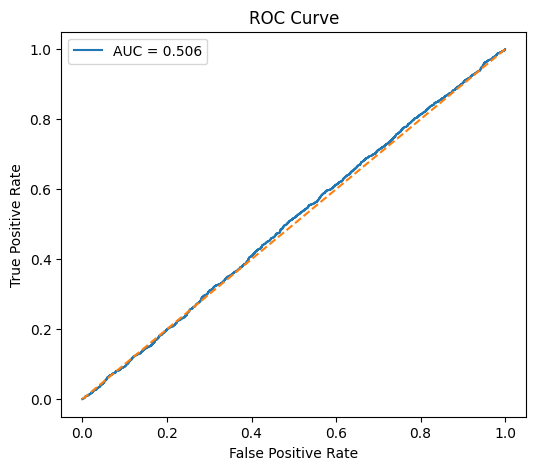

AUC Score: 0.5064569487416769


In [29]:
# STEP 24: ROC Curve and AUC Score
from sklearn.metrics import roc_curve, auc

y_prob = []

for images, labels in val_ds:
    
    predictions = model.predict(images)
    
    y_prob.extend(predictions.flatten())

y_prob = np.array(y_prob)

fpr, tpr, thresholds = roc_curve(y_true, y_prob)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))

plt.plot(fpr, tpr, label="AUC = %.3f" % roc_auc)

plt.plot([0,1], [0,1], linestyle="--")

plt.title("ROC Curve")

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.legend()

plt.show()

print("AUC Score:", roc_auc)

In [58]:
# STEP 25: Predict Single Image
from tensorflow.keras.preprocessing import image

img_path = r"C:\Users\yashw\Downloads\Kidney Stone Dataset\Stone\P195_RA_F_S_I19_EL.jpg"

img = image.load_img(img_path, target_size=(128,128))

img_array = image.img_to_array(img)

img_array = np.expand_dims(img_array, axis=0)

img_array = img_array / 255.0

prediction = model.predict(img_array)

confidence = prediction[0][0]
    
if confidence > 0.5:
        print("Prediction: Stone")
        print("Confidence:", confidence)
else:
        print("Prediction: Non-Stone")
        print("Confidence:", 1-confidence)

1/1 [==============================] - 0s 386ms/step
Prediction: Stone
Confidence: 0.711231


In [60]:
# STEP 26: Professional Prediction Function
# STEP 26.1: Define Function
def predict_kidney_stone(img_path):
    
    img = image.load_img(img_path, target_size=(128,128))
    
    img_array = image.img_to_array(img)
    
    img_array = np.expand_dims(img_array, axis=0)
    
    img_array = img_array / 255.0
    
    prediction = model.predict(img_array)
    
    confidence = prediction[0][0]
    
    if confidence > 0.5:
        print("Prediction: Stone")
        print("Confidence:", confidence)
    else:
        print("Prediction: Non-Stone")
        print("Confidence:", 1-confidence)

In [61]:
# STEP 26.2: Call Function
predict_kidney_stone(r"C:\Users\yashw\Downloads\Kidney Stone Dataset\Non Stone\P117_RA_M_NS_I11_EL.jpg")

1/1 [==============================] - 0s 33ms/step
Prediction: Non-Stone
Confidence: 0.9359317645430565


In [33]:
# STEP 27: Save Accuracy for Comparision
model_accuracies = {}
print("Accuracy storage initialized.")
model_accuracies["Layer Norm"] =  0.8112213611602783
print("Layer Norm accuracy added.")

Accuracy storage initialized.
Layer Norm accuracy added.


In [34]:
# STEP 28: Clear memory

import gc
tf.keras.backend.clear_session()
gc.collect()

print("Memory cleared successfully.")

Memory cleared successfully.


In [66]:
# STEP 29: CNN Model Architecture with Instance Normalization
# STEP 29.1: Add Custom Instance Normalization Layer

@tf.keras.utils.register_keras_serializable()
class InstanceNormalization(tf.keras.layers.Layer):
    def __init__(self, epsilon=1e-5, **kwargs):
        super(InstanceNormalization, self).__init__(**kwargs)
        self.epsilon = epsilon

    def build(self, input_shape):
        self.gamma = self.add_weight(
            name="gamma",
            shape=(input_shape[-1],),
            initializer="ones",
            trainable=True
        )
        self.beta = self.add_weight(
            name="beta",
            shape=(input_shape[-1],),
            initializer="zeros",
            trainable=True
        )

    def call(self, x):
        mean, variance = tf.nn.moments(x, axes=[1, 2], keepdims=True)
        x = (x - mean) / tf.sqrt(variance + self.epsilon)
        return self.gamma * x + self.beta

    def get_config(self):
        config = super().get_config()
        config.update({"epsilon": self.epsilon})
        return config

In [60]:
# STEP 29.2: Modified CNN with Instance Normalization

print("Building optimized CNN with Custom Instance Normalization...")

tf.keras.backend.clear_session()

model = tf.keras.models.Sequential([

    tf.keras.layers.Input(shape=(img_size, img_size, 3)),

    # Block 1
    tf.keras.layers.Conv2D(32, (3,3), padding='same',
                           kernel_initializer='he_normal'),
    InstanceNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(2),

    # Block 2
    tf.keras.layers.Conv2D(64, (3,3), padding='same',
                           kernel_initializer='he_normal'),
    InstanceNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(2),

    # Block 3
    tf.keras.layers.Conv2D(128, (3,3), padding='same',
                           kernel_initializer='he_normal'),
    InstanceNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(2),

    # Block 4
    tf.keras.layers.Conv2D(256, (3,3), padding='same',
                           kernel_initializer='he_normal'),
    InstanceNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(2),

    # Block 5
    tf.keras.layers.Conv2D(512, (3,3), padding='same',
                           kernel_initializer='he_normal'),
    InstanceNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(2),

    tf.keras.layers.GlobalAveragePooling2D(),

    # Dense block (use LayerNorm here instead)
    tf.keras.layers.Dense(256, kernel_initializer='he_normal'),
    tf.keras.layers.LayerNormalization(),
    tf.keras.layers.Activation('relu'),

    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(1, activation='sigmoid')
])

print("Custom Instance Normalized CNN built successfully.")

Building optimized CNN with Custom Instance Normalization...
Custom Instance Normalized CNN built successfully.


In [61]:
# STEP 29.3: Compile Model

model.compile(

    optimizer='adam',

    loss='binary_crossentropy',

    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]

)

print("Model compiled successfully.")

Model compiled successfully.


In [62]:
# STEP 29.4: View Model Summary
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 128, 128, 32)      896       
                                                                 
 instance_normalization (Ins  (None, 128, 128, 32)     64        
 tanceNormalization)                                             
                                                                 
 activation (Activation)     (None, 128, 128, 32)      0         
                                                                 
 max_pooling2d (MaxPooling2D  (None, 64, 64, 32)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 64, 64, 64)        18496     
                                                                 
 instance_normalization_1 (I  (None, 64, 64, 64)       1

In [20]:
# STEP 30: Training and Learning Rate Configuration
# STEP 30.1: Define Optimizer

lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    verbose=1
)
optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0001
)

print("Optimizer defined successfully.")

Optimizer defined successfully.


In [21]:
# STEP 30.2: Compile Model

model.compile(
    optimizer=optimizer,
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

print("Model compiled successfully.")

Model compiled successfully.


In [22]:
# STEP 30.3: Train the CNN Model

import gc
gc.collect()
tf.keras.backend.clear_session()

epochs = 30

history = model.fit(

    train_ds,
    
    validation_data=val_ds,
    
    epochs=epochs,

    callbacks=[early_stop, lr_scheduler],

    verbose = 1

)

print("Training completed successfully.")

Epoch 1/30
3227/3227 [==============================] - 205s 62ms/step - loss: 0.5481 - accuracy: 0.7142 - precision: 0.7298 - recall: 0.7628 - val_loss: 0.4015 - val_accuracy: 0.8216 - val_precision: 0.8168 - val_recall: 0.8765 - lr: 1.0000e-04
Epoch 2/30
3227/3227 [==============================] - 198s 61ms/step - loss: 0.3578 - accuracy: 0.8431 - precision: 0.8634 - recall: 0.8490 - val_loss: 0.2814 - val_accuracy: 0.8814 - val_precision: 0.8754 - val_recall: 0.9180 - lr: 1.0000e-04
Epoch 3/30
3227/3227 [==============================] - 200s 62ms/step - loss: 0.2600 - accuracy: 0.8908 - precision: 0.9095 - recall: 0.8900 - val_loss: 0.3657 - val_accuracy: 0.8402 - val_precision: 0.9727 - val_recall: 0.7339 - lr: 1.0000e-04
Epoch 4/30
3227/3227 [==============================] - 201s 62ms/step - loss: 0.2145 - accuracy: 0.9132 - precision: 0.9288 - recall: 0.9121 - val_loss: 0.2018 - val_accuracy: 0.9158 - val_precision: 0.9335 - val_recall: 0.9141 - lr: 1.0000e-04
Epoch 5/30
3227/

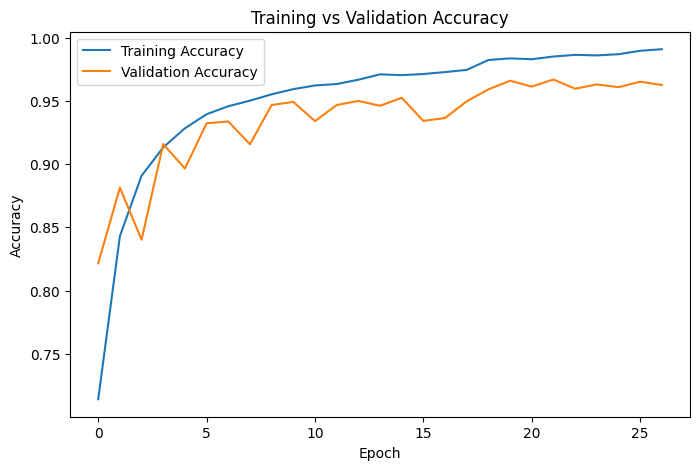

In [23]:
# STEP 30.4: Training vs Validation Accuracy Graph
plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Training Accuracy')

plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("Training vs Validation Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.show()

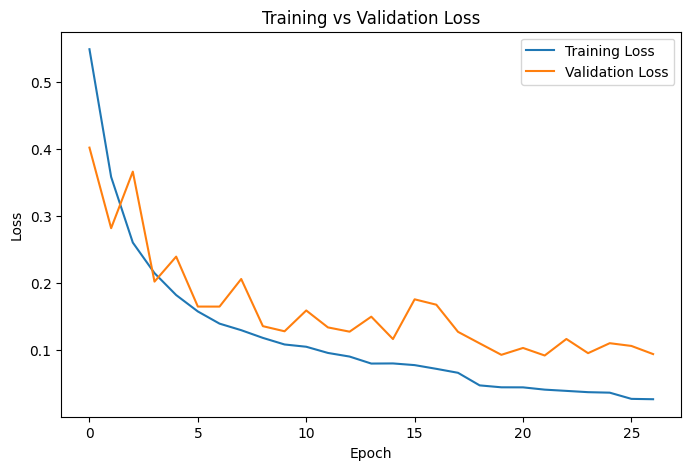

In [24]:
# STEP 30.5: Training vs Validation Loss Graph
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Training Loss')

plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Training vs Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.show()

In [25]:
# STEP 30.6: Save Trained Model

model.save("Kidney_Stone_Instance_Model.keras")
print("Model saved successfully.")

Model saved successfully.


In [67]:
from tensorflow.keras.models import load_model

model = load_model(
    "Kidney_Stone_Instance_Model.keras",
    custom_objects={"InstanceNormalization": InstanceNormalization}
)

print("Model loaded successfully.")

Model loaded successfully.


In [27]:
# STEP 31.1: Evaluate Model on Validation Dataset
val_loss, val_accuracy, val_precision, val_recall = model.evaluate(val_ds)

print("Validation Loss:", val_loss)
print("Validation Accuracy:", val_accuracy)
print("Validation Precision:", val_precision)
print("Validation Recall:", val_recall)

807/807 [==============================] - 11s 13ms/step - loss: 0.0917 - accuracy: 0.9668 - precision: 0.9625 - recall: 0.9786
Validation Loss: 0.09173116087913513
Validation Accuracy: 0.9668319821357727
Validation Precision: 0.962527334690094
Validation Recall: 0.97858726978302


In [69]:
# STEP 31.2: Get True Labels and Predictions
import numpy as np

y_true = []
y_pred = []

for images, labels in val_ds:
    
    predictions = model.predict(images)
    
    predicted_labels = (predictions > 0.5).astype(int)
    
    y_true.extend(labels.numpy())
    
    y_pred.extend(predicted_labels.flatten())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Predictions generated successfully.")

1/1 [==============================] - 0s 45ms/step
Predictions generated successfully.


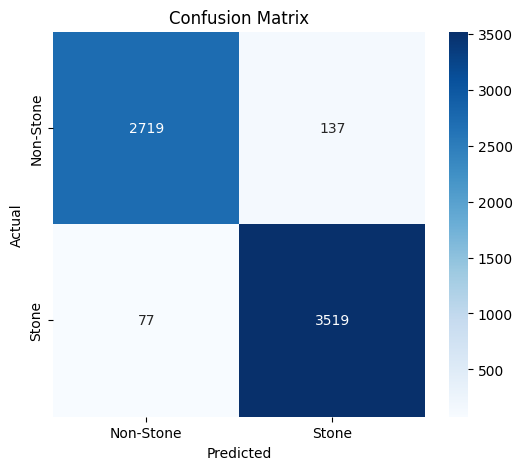

In [70]:
# STEP 31.3: Confusion Matrix

from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Non-Stone", "Stone"],
            yticklabels=["Non-Stone", "Stone"])

plt.title("Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

In [30]:
# STEP 31.4: Classification Report(Precision,Recall,F1,Score)
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=["Non-Stone", "Stone"]
))

              precision    recall  f1-score   support

   Non-Stone       0.97      0.95      0.96      2856
       Stone       0.96      0.98      0.97      3596

    accuracy                           0.97      6452
   macro avg       0.97      0.97      0.97      6452
weighted avg       0.97      0.97      0.97      6452



1/1 [==============================] - 0s 24ms/step


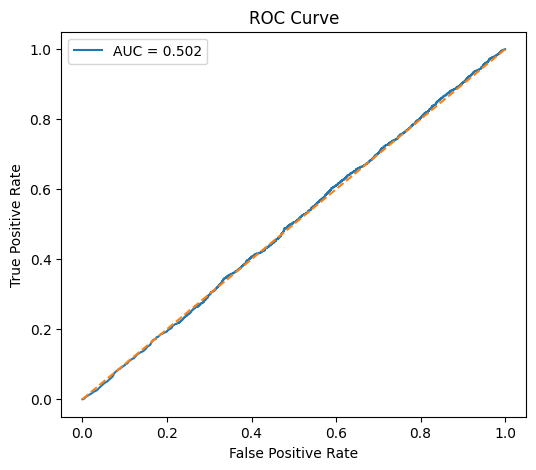

AUC Score: 0.5018450024614963


In [31]:
# STEP 32: ROC Curve and AUC Score
from sklearn.metrics import roc_curve, auc

y_prob = []

for images, labels in val_ds:
    
    predictions = model.predict(images)
    
    y_prob.extend(predictions.flatten())

y_prob = np.array(y_prob)

fpr, tpr, thresholds = roc_curve(y_true, y_prob)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))

plt.plot(fpr, tpr, label="AUC = %.3f" % roc_auc)

plt.plot([0,1], [0,1], linestyle="--")

plt.title("ROC Curve")

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.legend()

plt.show()

print("AUC Score:", roc_auc)

In [72]:
# STEP 33: Predict Single Image
from tensorflow.keras.preprocessing import image

img_path = r"C:\Users\yashw\Downloads\Kidney Stone Dataset\Stone\P195_RA_F_S_I19_EL.jpg"

img = image.load_img(img_path, target_size=(128,128))

img_array = image.img_to_array(img)

img_array = np.expand_dims(img_array, axis=0)

img_array = img_array / 255.0

prediction = model.predict(img_array)

confidence = prediction[0][0]
    
if confidence > 0.5:
        print("Prediction: Stone")
        print("Confidence:", confidence)
else:
        print("Prediction: Non-Stone")
        print("Confidence:", 1-confidence)

1/1 [==============================] - 0s 50ms/step
Prediction: Stone
Confidence: 0.999997


In [73]:
# STEP 34: Professional Prediction Function
# STEP 34.1: Define Function
def predict_kidney_stone(img_path):
    
    img = image.load_img(img_path, target_size=(128,128))
    
    img_array = image.img_to_array(img)
    
    img_array = np.expand_dims(img_array, axis=0)
    
    img_array = img_array / 255.0
    
    prediction = model.predict(img_array)
    
    confidence = prediction[0][0]
    
    if confidence > 0.5:
        print("Prediction: Stone")
        print("Confidence:", confidence)
    else:
        print("Prediction: Non-Stone")
        print("Confidence:", 1-confidence)

In [74]:
# STEP 34.2: Call Function
predict_kidney_stone(r"C:\Users\yashw\Downloads\Kidney Stone Dataset\Non Stone\P117_RA_M_NS_I11_EL.jpg")

1/1 [==============================] - 0s 34ms/step
Prediction: Non-Stone
Confidence: 0.9998292464733822


In [75]:
# STEP 35: Save Accuracy for Comparision
model_accuracies = {}
print("Accuracy storage initialized.")
model_accuracies["Instance Norm"] =  0.9668319821357727
print("Instance Norm accuracy added.")

Accuracy storage initialized.
Instance Norm accuracy added.


In [76]:
# STEP 36: Clear memory

import gc
tf.keras.backend.clear_session()
gc.collect()

print("Memory cleared successfully.")

Memory cleared successfully.


In [77]:
# STEP 37: CNN Model Architecture with Group Normalization
# STEP 37.1: Add Custom Group Normalization Layer

class GroupNormalization(tf.keras.layers.Layer):
    def __init__(self, groups=8, epsilon=1e-5, **kwargs):
        super(GroupNormalization, self).__init__(**kwargs)
        self.groups = groups
        self.epsilon = epsilon

    def build(self, input_shape):
        self.gamma = self.add_weight(
            shape=(input_shape[-1],),
            initializer="ones",
            trainable=True
        )
        self.beta = self.add_weight(
            shape=(input_shape[-1],),
            initializer="zeros",
            trainable=True
        )

    def call(self, x):
        input_shape = tf.shape(x)
        N, H, W, C = input_shape[0], input_shape[1], input_shape[2], input_shape[3]

        G = tf.minimum(self.groups, C)
        x = tf.reshape(x, [N, H, W, G, C // G])

        mean, var = tf.nn.moments(x, axes=[1, 2, 4], keepdims=True)
        x = (x - mean) / tf.sqrt(var + self.epsilon)

        x = tf.reshape(x, [N, H, W, C])
        return x * self.gamma + self.beta

    def get_config(self):
        config = super().get_config()
        config.update({
            "groups": self.groups,
            "epsilon": self.epsilon
        })
        return config

In [78]:
# STEP 37.2: Modified CNN with Group Normalization

print("Building optimized CNN with Custom Group Normalization...")

tf.keras.backend.clear_session()

model = tf.keras.models.Sequential([

    tf.keras.layers.Input(shape=(img_size, img_size, 3)),

    # Block 1
    tf.keras.layers.Conv2D(32, (3,3), padding='same',
                           kernel_initializer='he_normal'),
    GroupNormalization(groups=8),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(2),

    # Block 2
    tf.keras.layers.Conv2D(64, (3,3), padding='same',
                           kernel_initializer='he_normal'),
    GroupNormalization(groups=8),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(2),

    # Block 3
    tf.keras.layers.Conv2D(128, (3,3), padding='same',
                           kernel_initializer='he_normal'),
    GroupNormalization(groups=16),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(2),

    # Block 4
    tf.keras.layers.Conv2D(256, (3,3), padding='same',
                           kernel_initializer='he_normal'),
    GroupNormalization(groups=16),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(2),

    # Block 5
    tf.keras.layers.Conv2D(512, (3,3), padding='same',
                           kernel_initializer='he_normal'),
    GroupNormalization(groups=32),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(2),

    tf.keras.layers.GlobalAveragePooling2D(),

    # Dense block
    tf.keras.layers.Dense(256, kernel_initializer='he_normal'),
    tf.keras.layers.LayerNormalization(),  # safer for dense layer
    tf.keras.layers.Activation('relu'),

    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(1, activation='sigmoid')

])

print("Custom Group Normalized CNN built successfully.")

Building optimized CNN with Custom Group Normalization...
Custom Group Normalized CNN built successfully.


In [79]:
# STEP 37.3: Compile Model

model.compile(

    optimizer='adam',

    loss='binary_crossentropy',

    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]

)

print("Model compiled successfully.")

Model compiled successfully.


In [80]:
# STEP 37.4: View Model Summary
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 128, 128, 32)      896       
                                                                 
 group_normalization (GroupN  (None, 128, 128, 32)     64        
 ormalization)                                                   
                                                                 
 activation (Activation)     (None, 128, 128, 32)      0         
                                                                 
 max_pooling2d (MaxPooling2D  (None, 64, 64, 32)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 64, 64, 64)        18496     
                                                                 
 group_normalization_1 (Grou  (None, 64, 64, 64)       1

In [81]:
# STEP 38: Training and Learning Rate Configuration
# STEP 38.1: Define Optimizer

lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    verbose=1
)
optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0001
)

print("Optimizer defined successfully.")

Optimizer defined successfully.


In [82]:
# STEP 38.2: Compile Model

model.compile(
    optimizer=optimizer,
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

print("Model compiled successfully.")

Model compiled successfully.


In [83]:
# STEP 38.3: Train the CNN Model

import gc
gc.collect()
tf.keras.backend.clear_session()

epochs = 30

history = model.fit(

    train_ds,
    
    validation_data=val_ds,
    
    epochs=epochs,

    callbacks=[early_stop, lr_scheduler],

    verbose = 1

)

print("Training completed successfully.")

Epoch 1/30
3227/3227 [==============================] - 201s 62ms/step - loss: 0.6419 - accuracy: 0.6335 - precision: 0.6500 - recall: 0.7231 - val_loss: 0.5134 - val_accuracy: 0.7477 - val_precision: 0.8322 - val_recall: 0.6855 - lr: 1.0000e-04
Epoch 2/30
3227/3227 [==============================] - 198s 61ms/step - loss: 0.4938 - accuracy: 0.7563 - precision: 0.7913 - recall: 0.7565 - val_loss: 0.3671 - val_accuracy: 0.8467 - val_precision: 0.8821 - val_recall: 0.8368 - lr: 1.0000e-04
Epoch 3/30
3227/3227 [==============================] - 198s 61ms/step - loss: 0.3904 - accuracy: 0.8211 - precision: 0.8606 - recall: 0.8052 - val_loss: 0.3131 - val_accuracy: 0.8790 - val_precision: 0.9220 - val_recall: 0.8551 - lr: 1.0000e-04
Epoch 4/30
3227/3227 [==============================] - 199s 62ms/step - loss: 0.3176 - accuracy: 0.8611 - precision: 0.8935 - recall: 0.8487 - val_loss: 0.2225 - val_accuracy: 0.9092 - val_precision: 0.9237 - val_recall: 0.9124 - lr: 1.0000e-04
Epoch 5/30
3227/

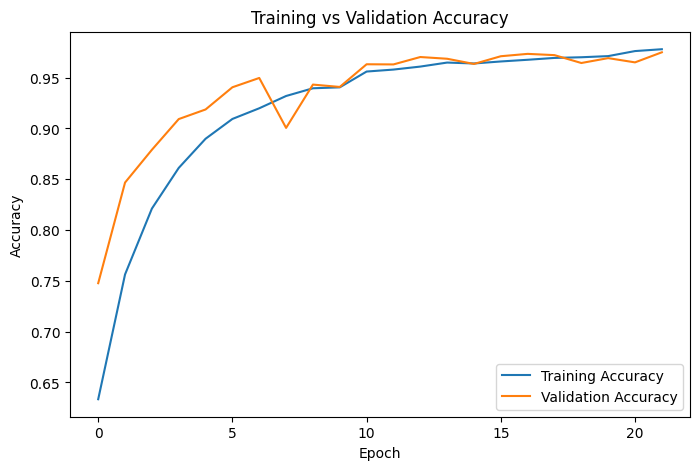

In [85]:
# STEP 38.4: Training vs Validation Accuracy Graph
plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Training Accuracy')

plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("Training vs Validation Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.show()

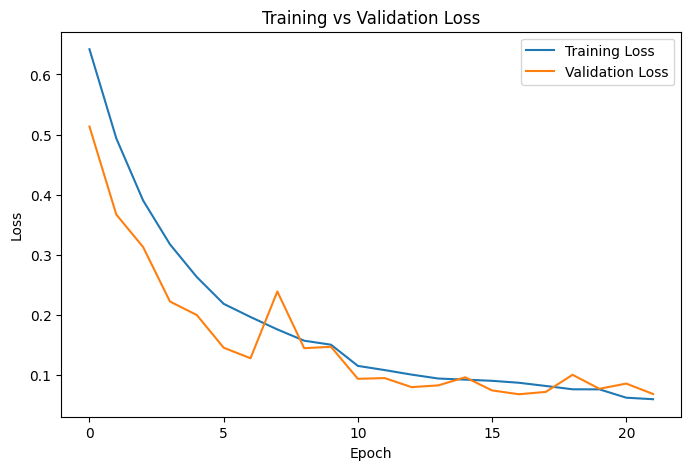

In [86]:
# STEP 38.5: Training vs Validation Loss Graph
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Training Loss')

plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Training vs Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.show()

In [96]:
# STEP 39.1: Evaluate Model on Validation Dataset
val_loss, val_accuracy, val_precision, val_recall = model.evaluate(val_ds)

print("Validation Loss:", val_loss)
print("Validation Accuracy:", val_accuracy)
print("Validation Precision:", val_precision)
print("Validation Recall:", val_recall)

807/807 [==============================] - 11s 14ms/step - loss: 0.0685 - accuracy: 0.9733 - precision: 0.9858 - recall: 0.9661
Validation Loss: 0.06849544495344162
Validation Accuracy: 0.9733415842056274
Validation Precision: 0.9858116507530212
Validation Recall: 0.9660733938217163


In [97]:
# STEP 39.2: Get True Labels and Predictions
import numpy as np

y_true = []
y_pred = []

for images, labels in val_ds:
    
    predictions = model.predict(images)
    
    predicted_labels = (predictions > 0.5).astype(int)
    
    y_true.extend(labels.numpy())
    
    y_pred.extend(predicted_labels.flatten())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Predictions generated successfully.")

1/1 [==============================] - 0s 28ms/step
Predictions generated successfully.


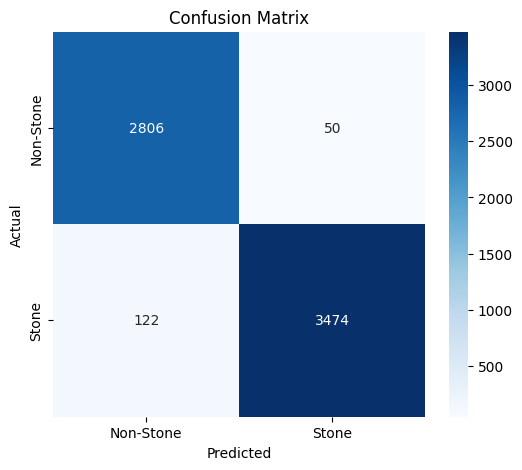

In [98]:
# STEP 39.3: Confusion Matrix

from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Non-Stone", "Stone"],
            yticklabels=["Non-Stone", "Stone"])

plt.title("Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

In [99]:
# STEP 39.4: Classification Report(Precision,Recall,F1,Score)
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=["Non-Stone", "Stone"]
))

              precision    recall  f1-score   support

   Non-Stone       0.96      0.98      0.97      2856
       Stone       0.99      0.97      0.98      3596

    accuracy                           0.97      6452
   macro avg       0.97      0.97      0.97      6452
weighted avg       0.97      0.97      0.97      6452



1/1 [==============================] - 0s 26ms/step


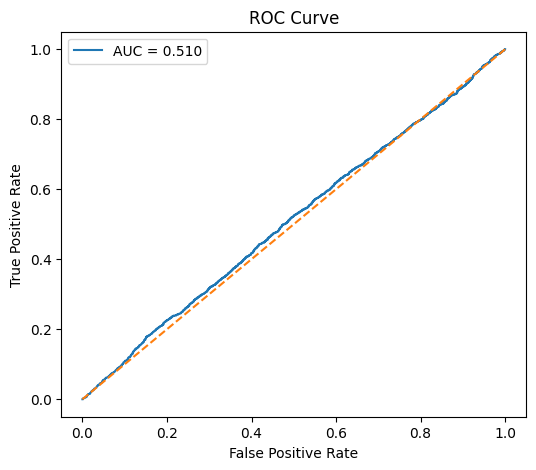

AUC Score: 0.5104655947473539


In [100]:
# STEP 40: ROC Curve and AUC Score
from sklearn.metrics import roc_curve, auc

y_prob = []

for images, labels in val_ds:
    
    predictions = model.predict(images)
    
    y_prob.extend(predictions.flatten())

y_prob = np.array(y_prob)

fpr, tpr, thresholds = roc_curve(y_true, y_prob)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))

plt.plot(fpr, tpr, label="AUC = %.3f" % roc_auc)

plt.plot([0,1], [0,1], linestyle="--")

plt.title("ROC Curve")

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.legend()

plt.show()

print("AUC Score:", roc_auc)

In [103]:
# STEP 41: Predict Single Image
from tensorflow.keras.preprocessing import image

img_path = r"C:\Users\yashw\Downloads\Kidney Stone Dataset\Stone\P195_RA_F_S_I19_EL.jpg"

img = image.load_img(img_path, target_size=(128,128))

img_array = image.img_to_array(img)

img_array = np.expand_dims(img_array, axis=0)

img_array = img_array / 255.0

prediction = model.predict(img_array)

confidence = prediction[0][0]
    
if confidence > 0.5:
        print("Prediction: Stone")
        print("Confidence:", confidence)
else:
        print("Prediction: Non-Stone")
        print("Confidence:", 1-confidence)

1/1 [==============================] - 0s 34ms/step
Prediction: Stone
Confidence: 0.9999423


In [104]:
# STEP 42: Professional Prediction Function
# STEP 42.1: Define Function
def predict_kidney_stone(img_path):
    
    img = image.load_img(img_path, target_size=(128,128))
    
    img_array = image.img_to_array(img)
    
    img_array = np.expand_dims(img_array, axis=0)
    
    img_array = img_array / 255.0
    
    prediction = model.predict(img_array)
    
    confidence = prediction[0][0]
    
    if confidence > 0.5:
        print("Prediction: Stone")
        print("Confidence:", confidence)
    else:
        print("Prediction: Non-Stone")
        print("Confidence:", 1-confidence)

In [105]:
# STEP 42.2: Call Function
predict_kidney_stone(r"C:\Users\yashw\Downloads\Kidney Stone Dataset\Non Stone\P117_RA_M_NS_I11_EL.jpg")

1/1 [==============================] - 0s 34ms/step
Prediction: Non-Stone
Confidence: 0.999146094720345


In [106]:
# STEP 43.1: Save Accuracy for Comparision
model_accuracies = {}
print("Accuracy storage initialized.")
model_accuracies["Batch Norm"] = 0.9733415842056274
print("Batch Norm accuracy added.")

Accuracy storage initialized.
Batch Norm accuracy added.


In [124]:
# STEP 43.2: Storing the accuracies of all 5 Models

model_accuracies = {
    "Pure CNN": 99.05455708503723,
    "Batch Norm": 98.10911417007446,
    "Layer Norm": 81.12213611602783,
    "Instance Norm": 96.68319821357727,
    "Group Norm": 97.33415842056274
}

In [125]:
# STEP 44.1: Print Comparison Table

print("Model Performance Comparison:\n")

for model_name, acc in model_accuracies.items():
    print(f"{model_name}: {acc:.2f}%")

Model Performance Comparison:

Pure CNN: 99.05%
Batch Norm: 98.11%
Layer Norm: 81.12%
Instance Norm: 96.68%
Group Norm: 97.33%




In [130]:
# STEP 44.2: Visualize Comparison
import matplotlib.pyplot as plt

models = list(model_accuracies.keys())
accuracies = list(model_accuracies.values())

plt.figure(figsize=(10,6))
plt.bar(models, accuracies)

plt.title("Comparison of Normalization Techniques")
plt.ylabel("Validation Accuracy (%)")
plt.xticks(rotation=30)
plt.ylim(0,100)

for i, v in enumerate(accuracies):
    plt.text(v + 0.3, i, f"{v:.2f}%", va='center')

plt.show()

In [132]:
# STEP 45: Identify Best Model Automatically
best_model = max(model_accuracies, key=model_accuracies.get)

print(f"\nBest Performing Model: {best_model}")
print(f"Validation Accuracy: {model_accuracies[best_model]:.2f}%")


Best Performing Model: Pure CNN
Validation Accuracy: 99.05%


In [133]:
# STEP 46: Save Results to CSV (Professional Move)
import pandas as pd

df = pd.DataFrame(
    model_accuracies.items(),
    columns=["Model", "Validation Accuracy (%)"]
)

df.to_csv("model_comparison_results.csv", index=False)

print("Comparison results saved to CSV.")

Comparison results saved to CSV.


1/1 [==============================] - 0s 36ms/step


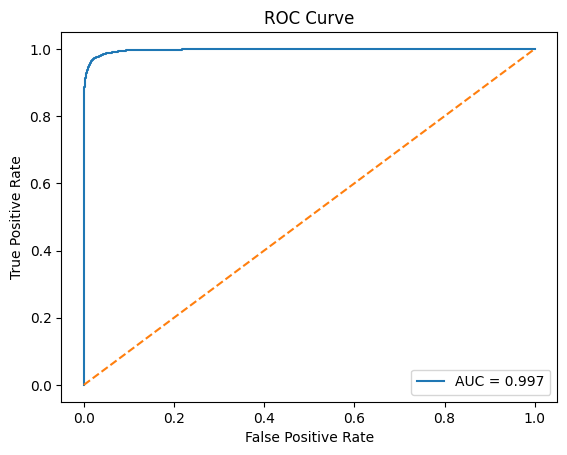

In [134]:
# STEP 47: Final ROC Curve For Best Model

from sklearn.metrics import roc_curve, auc
import numpy as np

y_true = []
y_pred = []

for images, labels in val_ds:
    predictions = model.predict(images)
    y_true.extend(labels.numpy())
    y_pred.extend(predictions.flatten())

fpr, tpr, _ = roc_curve(y_true, y_pred)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0,1], [0,1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [4]:
from tensorflow.keras.models import load_model

model = load_model("kidney_stone_pureCNN.keras")
print("Model loaded successfully.")
model = load_model("kidney_stone_BatchNorm.keras")
print("Model loaded successfully.")

Model loaded successfully.
Model loaded successfully.


In [3]:
pip install tensorflow-addons==0.18.0

Note: you may need to restart the kernel to use updated packages.


In [1]:
import tensorflow as tf
from tensorflow.keras.layers import Layer

class CustomInstanceNormalization(Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.norm = tf.keras.layers.LayerNormalization()

    def call(self, inputs):
        return self.norm(inputs)

In [3]:
import tensorflow as tf

@tf.keras.utils.register_keras_serializable()
class InstanceNormalization(tf.keras.layers.Layer):
    def __init__(self, epsilon=1e-5, **kwargs):
        super(InstanceNormalization, self).__init__(**kwargs)
        self.epsilon = epsilon

    def build(self, input_shape):
        self.gamma = self.add_weight(
            name="gamma",
            shape=(input_shape[-1],),
            initializer="ones",
            trainable=True
        )
        self.beta = self.add_weight(
            name="beta",
            shape=(input_shape[-1],),
            initializer="zeros",
            trainable=True
        )

    def call(self, x):
        mean, variance = tf.nn.moments(x, axes=[1, 2], keepdims=True)
        x = (x - mean) / tf.sqrt(variance + self.epsilon)
        return self.gamma * x + self.beta

    def get_config(self):
        config = super().get_config()
        config.update({"epsilon": self.epsilon})
        return config


CustomInstanceNormalization = InstanceNormalization


from tensorflow.keras.models import load_model

model = load_model(
    "Kidney_Stone_Instance_Model.keras",
    custom_objects={
        "InstanceNormalization": InstanceNormalization,
        "CustomInstanceNormalization": CustomInstanceNormalization
    },
    compile=False
)

print("MODEL LOADED SUCCESSFULLY")

MODEL LOADED SUCCESSFULLY


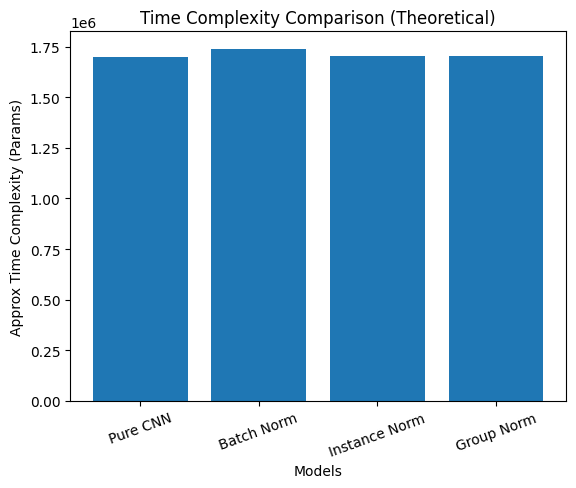


Approx Time Complexity:
Pure CNN: 1700161 params
Batch Norm: 1737921 params
Instance Norm: 1702657 params
Group Norm: 1702657 params

⚡ Fastest Model (Theoretical): Pure CNN


In [11]:
#STEP 48: Time Complexity Analysis(Theoretical - Based on Parameter Count)

import matplotlib.pyplot as plt

models = {
    "Pure CNN": 1700161,
    "Batch Norm": 1737921,
    "Instance Norm": 1702657,
    "Group Norm": 1702657
}


time_results = models

# Plot
plt.figure()
plt.bar(time_results.keys(), time_results.values())
plt.xlabel("Models")
plt.ylabel("Approx Time Complexity (Params)")
plt.title("Time Complexity Comparison (Theoretical)")
plt.xticks(rotation=20)
plt.show()

# Best (lowest params = fastest)
best_time_model = min(time_results, key=time_results.get)

print("\nApprox Time Complexity:")
for k, v in time_results.items():
    print(f"{k}: {v} params")

print(f"\n⚡ Fastest Model (Theoretical): {best_time_model}")

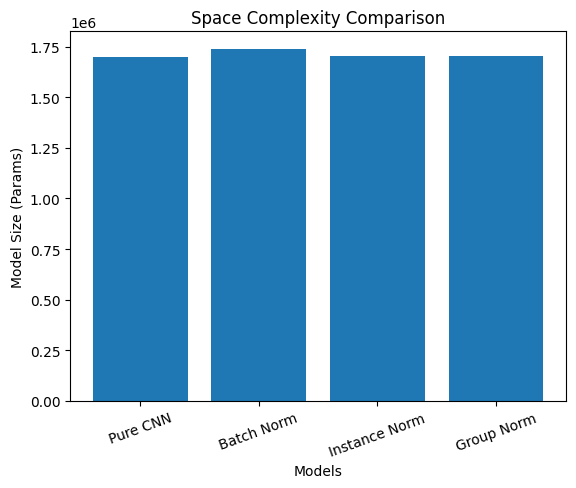


Space Complexity:
Pure CNN: 1700161 params
Batch Norm: 1737921 params
Instance Norm: 1702657 params
Group Norm: 1702657 params

💾 Most Efficient Model: Pure CNN


In [12]:
# STEP 49: Space Complexity Analysis(Model Size using Parameter Count)

import matplotlib.pyplot as plt


space_results = models

plt.figure()
plt.bar(space_results.keys(), space_results.values())
plt.xlabel("Models")
plt.ylabel("Model Size (Params)")
plt.title("Space Complexity Comparison")
plt.xticks(rotation=20)
plt.show()

best_space_model = min(space_results, key=space_results.get)

print("\nSpace Complexity:")
for k, v in space_results.items():
    print(f"{k}: {v} params")

print(f"\n💾 Most Efficient Model: {best_space_model}")

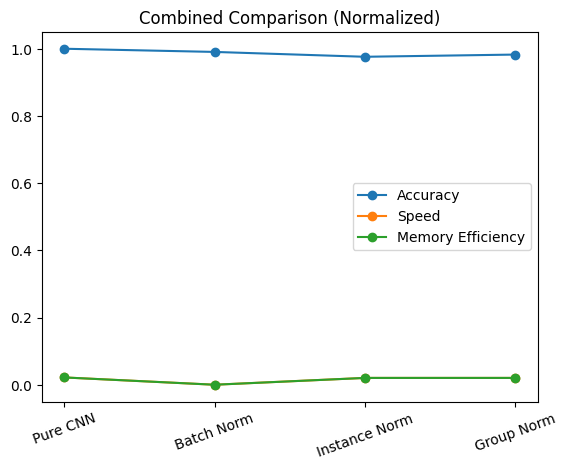


Model Scores:
Pure CNN: 0.6087
Batch Norm: 0.5943
Instance Norm: 0.5938
Group Norm: 0.5977

🏆 Best Overall Model: Pure CNN


In [13]:
# STEP 50: Combined Model Evaluation(Accuracy+Time+Space Analysis)

import matplotlib.pyplot as plt
import numpy as np

models_list = ["Pure CNN", "Batch Norm", "Instance Norm", "Group Norm"]

accuracy = [99.05, 98.11, 96.68, 97.33]
params = [models[m] for m in models_list]

# Normalize
acc_norm = np.array(accuracy) / max(accuracy)
time_norm = 1 - (np.array(params) / max(params))
space_norm = 1 - (np.array(params) / max(params))

# Plot
plt.figure()
plt.plot(models_list, acc_norm, marker='o', label="Accuracy")
plt.plot(models_list, time_norm, marker='o', label="Speed")
plt.plot(models_list, space_norm, marker='o', label="Memory Efficiency")

plt.title("Combined Comparison (Normalized)")
plt.legend()
plt.xticks(rotation=20)
plt.show()

# Scoring
scores = {}
for i, m in enumerate(models_list):
    score = (0.6 * acc_norm[i]) + (0.2 * time_norm[i]) + (0.2 * space_norm[i])
    scores[m] = score

best_model = max(scores, key=scores.get)

print("\nModel Scores:")
for k, v in scores.items():
    print(f"{k}: {v:.4f}")

print(f"\n🏆 Best Overall Model: {best_model}")